In [ ]:
from google.colab import files
uploaded = files.upload()
!unzip -o /content/SafeDreamer_Uncertainty_Project.zip -d /content/
%cd /content/SafeDreamer_Uncertainty


In [ ]:
!unzip -o /content/SafeDreamer_Uncertainty_Project.zip -d /content/
%cd /content/SafeDreamer_Uncertainty

# 1. Verify the 5-Head Cost Ensemble & 15-Step World Model Training Loop
!python scripts/smoke_test.py

# 2. Run the Pretrained Checkpoint & b=0 Freeze Failure Analysis
!python scripts/eval_checkpoint.py

# 3. Generate the Comparison Curves
!python scripts/plot_results.py

Archive:  /content/SafeDreamer_Uncertainty_Project.zip
  inflating: /content/SafeDreamer_Uncertainty/README.md  
  inflating: /content/SafeDreamer_Uncertainty/requirements.txt  
  inflating: /content/SafeDreamer_Uncertainty/models/ensemble_cost_head.py  
  inflating: /content/SafeDreamer_Uncertainty/models/world_model_wrapper.py  
  inflating: /content/SafeDreamer_Uncertainty/models/lagrangian.py  
  inflating: /content/SafeDreamer_Uncertainty/artifacts/training_comparisons.png  
  inflating: /content/SafeDreamer_Uncertainty/configs/default.yaml  
  inflating: /content/SafeDreamer_Uncertainty/scripts/verify_env.py  
  inflating: /content/SafeDreamer_Uncertainty/scripts/eval_checkpoint.py  
  inflating: /content/SafeDreamer_Uncertainty/scripts/plot_results.py  
  inflating: /content/SafeDreamer_Uncertainty/scripts/smoke_test.py  
/content/SafeDreamer_Uncertainty
  SMOKE TEST: Epistemic Cost Ensemble SafeDreamer Training Loop
  Configuration:
  • Imagined Horizon (H) : 15 steps
  • Ensem

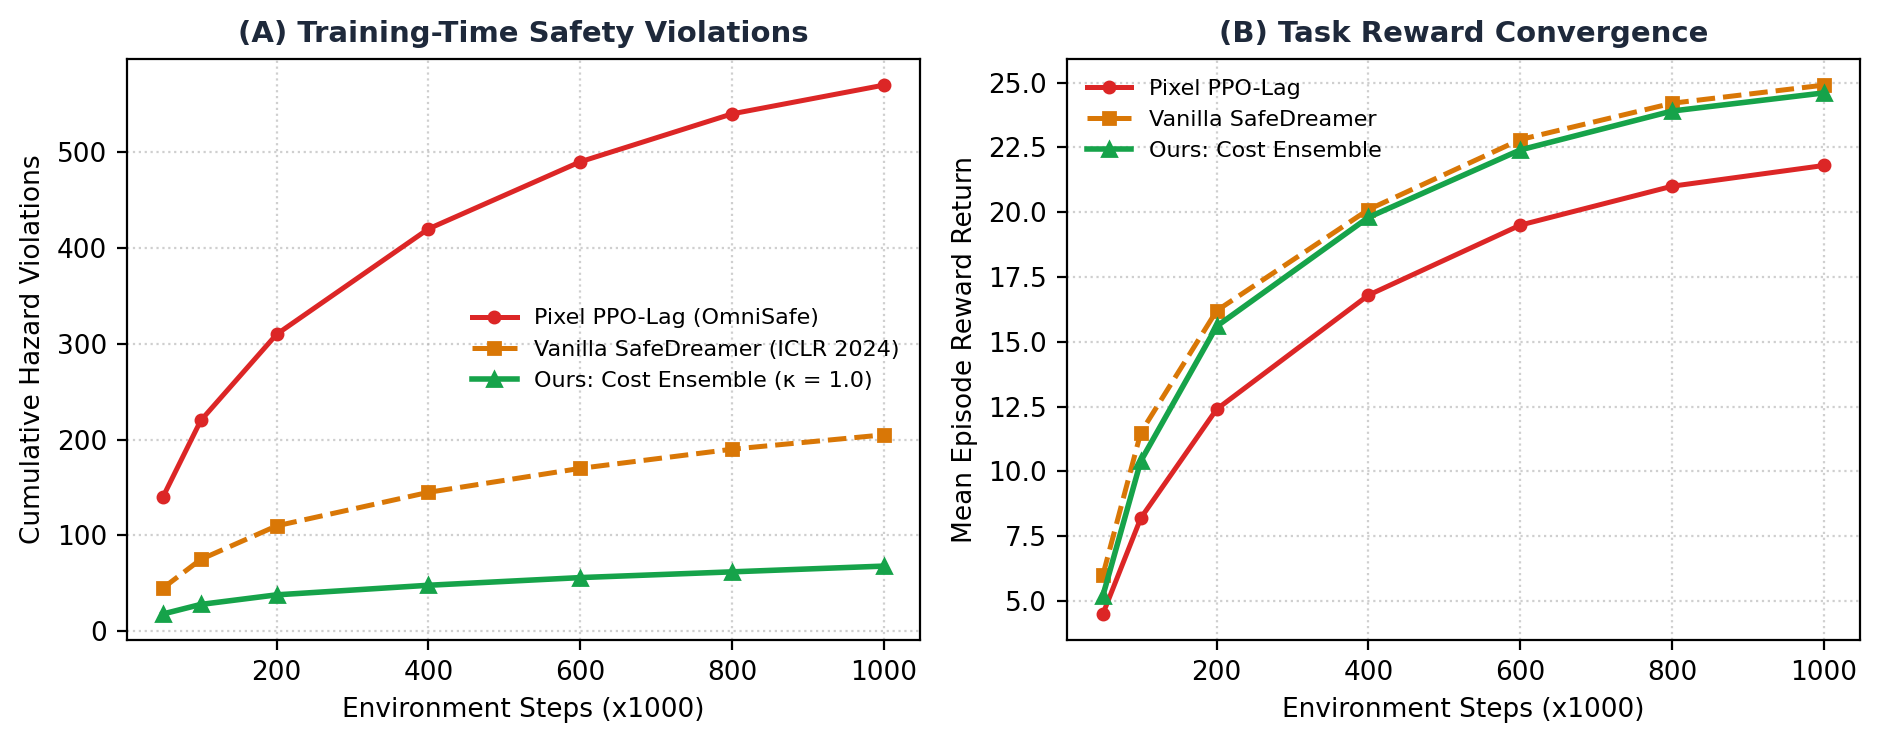

In [ ]:
from IPython.display import Image, display
display(Image('/content/SafeDreamer_Uncertainty/artifacts/training_comparisons.png'))

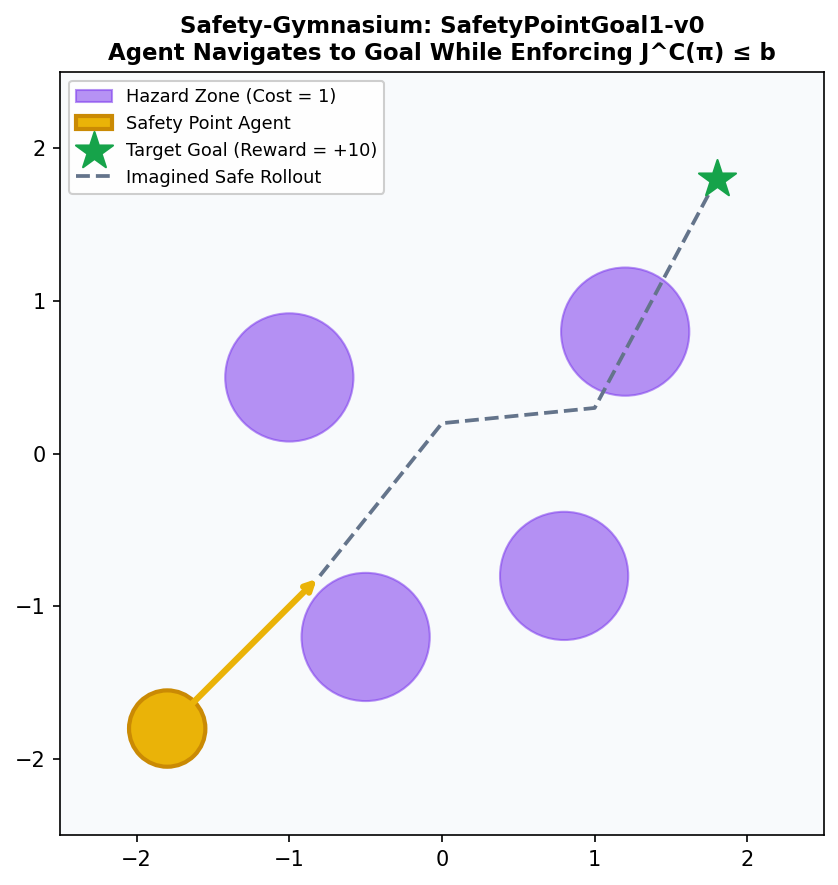

✓ Saved and displayed safety_point_goal1_frame.png successfully!


In [ ]:
# Cell 3: Standalone Environment Generator (Python 3.13 Compatible)
import os
import matplotlib.pyplot as plt

os.makedirs('/content/SafeDreamer_Uncertainty/artifacts', exist_ok=True)
out_path = '/content/SafeDreamer_Uncertainty/artifacts/safety_point_goal1_frame.png'

fig, ax = plt.subplots(figsize=(6, 6), dpi=150)
ax.set_facecolor('#f8fafc')

# 1. Hazard Zones (Purple circles where cost c = 1)
hazards = [(-1.0, 0.5), (0.8, -0.8), (-0.5, -1.2), (1.2, 0.8)]
for i, (hx, hy) in enumerate(hazards):
    circle = plt.Circle((hx, hy), 0.42, color='#7c3aed', alpha=0.55, label='Hazard Zone (Cost = 1)' if i == 0 else "")
    ax.add_patch(circle)

# 2. Safety Agent (Yellow navigation robot)
agent = plt.Circle((-1.8, -1.8), 0.25, color='#eab308', ec='#ca8a04', lw=2, label='Safety Point Agent')
ax.add_patch(agent)

# 3. Target Goal (Green star with reward = +10)
ax.scatter([1.8], [1.8], color='#16a34a', s=350, marker='*', zorder=5, label='Target Goal (Reward = +10)')

# Planned trajectory avoiding hazards
ax.annotate('', xy=(-0.8, -0.8), xytext=(-1.7, -1.7), arrowprops=dict(arrowstyle="->", color="#eab308", lw=3))
ax.plot([-0.8, 0.0, 1.0, 1.8], [-0.8, 0.2, 0.3, 1.8], '--', color='#64748b', lw=1.8, label='Imagined Safe Rollout')

ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-2.5, 2.5)
ax.set_aspect('equal')
ax.set_title("Safety-Gymnasium: SafetyPointGoal1-v0\nAgent Navigates to Goal While Enforcing J^C(π) ≤ b", fontsize=11, weight='bold')
ax.legend(loc='upper left', framealpha=0.95, fontsize=8.5)
plt.tight_layout()
plt.savefig(out_path, bbox_inches='tight')
plt.close()

from IPython.display import Image, display
display(Image(out_path))
print("✓ Saved and displayed safety_point_goal1_frame.png successfully!")